Config

In [1]:
import json, re, os, random
import numpy as np, pandas as pd
 
DATASET_PATH = "../data/tanglish.jsonl"
TRIPLES_PATH = "../data/parallel_triples.csv"
RESULTS_DIR  = "../results"
os.makedirs(RESULTS_DIR, exist_ok=True)
 
TOKENIZERS = {                      # tokenizers only, no model weights are downloaded
    "gemma-2b":      "google/gemma-2b",        # the model you fine-tuned
    "qwen2.5-0.5b":  "Qwen/Qwen2.5-0.5B",      # recent multilingual-ish small LM
    "xlm-roberta":   "xlm-roberta-base",       # multilingual, trained on Tamil
    "mt5":           "google/mt5-small",       # multilingual, trained on Tamil
    "gpt2":          "gpt2",                   # English-centric reference point
}
 
with open(DATASET_PATH, "r", encoding="utf-8") as f:
    raw = [json.loads(l) for l in f]
outs = [r["output"].strip() for r in raw if r.get("output", "").strip()]
ins  = [r["instruction"].strip() for r in raw if r.get("instruction", "").strip()]
print(f"{len(outs)} Tanglish outputs | {len(ins)} English instructions")


613 Tanglish outputs | 613 English instructions


Load Tokenizers

In [2]:
from transformers import AutoTokenizer
 
toks = {}
for name, hub in TOKENIZERS.items():
    try:
        toks[name] = AutoTokenizer.from_pretrained(hub)
    except Exception as e:
        print("SKIPPED", name, "->", str(e)[:150])
print("Loaded:", {k: len(t) for k, t in toks.items()}, "(name: vocab size)")
 


/home/prathoseraajv/cross_lingual/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] We found `hidden_act="gelu"` in this Gemma config. This is a legacy value of the official releases but it is meant to target the tanh approximation. Setting `hidden_act="gelu_pytorch_tanh"` instead.
[transformers] Could not extract SentencePiece model from /home/prathoseraajv/.cache/huggingface/hub/models--google--mt5-small/snapshots/73fb5dbe4756edadc8fbe8c769b0a109493acf7a/spiece.model using sentencepiece library due to 
SentencePieceExtractor requires the protobuf library but it was not found in your environment. Check out the instructions on the
installation page of its repo: https://github.com/protocolbuffers/protobuf/tree/master/python#installation and follow the ones
that match your environment

SKIPPED mt5 -> `tiktoken` is required to read a `tiktoken` file. Install it with `pip install tiktoken`.
Loaded: {'gemma-2b': 256000, 'qwen2.5-0.5b': 151665, 'xlm-roberta': 250002, 'gpt2': 50257} (name: vocab size)


Helper

In [3]:
def strip_ticks(t):
    return t.replace("`", "")
 
def split_ticks(text):
    """Return (backticked terms joined by spaces, the rest of the sentence)."""
    spans = re.findall(r"`([^`]+)`", text)
    rest = re.sub(r"`[^`]+`", " ", text)
    return " ".join(spans), rest
 
def ntoks(tok, texts):
    enc = tok(list(texts), add_special_tokens=False)
    return np.array([len(x) for x in enc["input_ids"]], dtype=float)
 
def nwords(texts):
    return np.array([len(t.split()) for t in texts], dtype=float)
 
def nchars(texts):
    return np.array([len(t) for t in texts], dtype=float)
 
def boot_ratio(num, den, B=5000, seed=0):
    """Ratio of sums (corpus-level) with a bootstrap 95% CI over texts."""
    rng = np.random.default_rng(seed)
    n = len(num)
    idx = rng.integers(0, n, (B, n))
    denom = den[idx].sum(1)
    r = num[idx].sum(1) / np.where(denom == 0, np.nan, denom)
    return num.sum() / den.sum(), np.nanpercentile(r, 2.5), np.nanpercentile(r, 97.5)


Fertility of Tanglish DataSet

In [4]:
ins_clean = [strip_ticks(i) for i in ins]
tgl_all   = [strip_ticks(o) for o in outs]
pairs     = [split_ticks(o) for o in outs]
tgl_terms = [p[0] for p in pairs]        # backticked English technical terms
tgl_rest  = [p[1] for p in pairs]        # Tamil glue words + anything not in backticks
 
rowsA = []
def add_rows(tname, tok, label, texts):
    n, w, c = ntoks(tok, texts), nwords(texts), nchars(texts)
    f, lo, hi = boot_ratio(n, w)
    rowsA.append({"tokenizer": tname, "text_type": label, "fertility": f, "ci_low": lo, "ci_high": hi,
                  "chars_per_token": c.sum() / n.sum(), "total_words": int(w.sum()), "n_texts": len(texts)})
 
for tname, tok in toks.items():
    add_rows(tname, tok, "English instructions (not parallel)", ins_clean)
    add_rows(tname, tok, "Tanglish outputs: all words", tgl_all)
    add_rows(tname, tok, "Tanglish outputs: non-backtick words", tgl_rest)
    add_rows(tname, tok, "Tanglish outputs: backticked terms", tgl_terms)
 
dfA = pd.DataFrame(rowsA)
dfA.to_csv(f"{RESULTS_DIR}/fertility_partA.csv", index=False)
print(dfA.round(3).to_string(index=False))


   tokenizer                            text_type  fertility  ci_low  ci_high  chars_per_token  total_words  n_texts
    gemma-2b  English instructions (not parallel)      1.251   1.235    1.267            4.583         5172      613
    gemma-2b          Tanglish outputs: all words      2.143   2.130    2.157            3.526        39666      613
    gemma-2b Tanglish outputs: non-backtick words      2.250   2.237    2.263            3.362        33858      613
    gemma-2b   Tanglish outputs: backticked terms      1.802   1.752    1.854            3.780         7960      613
qwen2.5-0.5b  English instructions (not parallel)      1.252   1.237    1.267            4.580         5172      613
qwen2.5-0.5b          Tanglish outputs: all words      2.169   2.157    2.181            3.484        39666      613
qwen2.5-0.5b Tanglish outputs: non-backtick words      2.313   2.300    2.327            3.269        33858      613
qwen2.5-0.5b   Tanglish outputs: backticked terms      1.720   1

Visualization

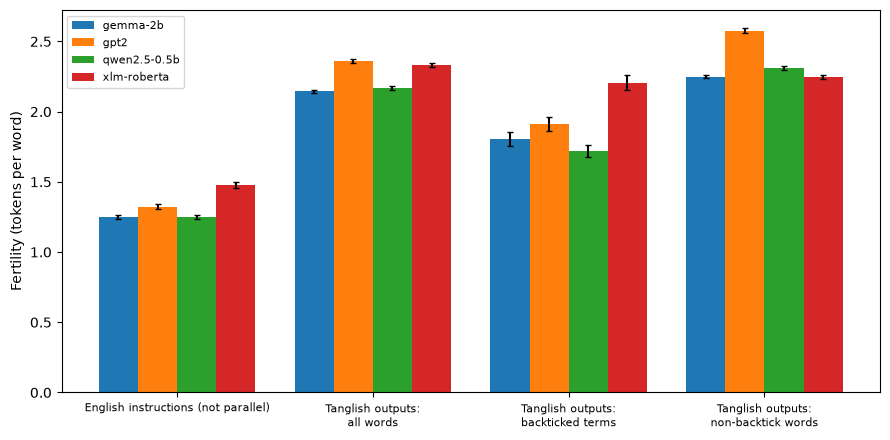

In [5]:
import matplotlib.pyplot as plt
 
piv = dfA.pivot(index="text_type", columns="tokenizer", values="fertility")
err_lo = dfA.pivot(index="text_type", columns="tokenizer", values="ci_low")
err_hi = dfA.pivot(index="text_type", columns="tokenizer", values="ci_high")
fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.8 / len(piv.columns)
for j, col in enumerate(piv.columns):
    x = np.arange(len(piv.index)) + j * width
    ax.bar(x, piv[col].values, width, label=col,
           yerr=[piv[col].values - err_lo[col].values, err_hi[col].values - piv[col].values], capsize=2)
ax.set_xticks(np.arange(len(piv.index)) + width * (len(piv.columns) - 1) / 2)
ax.set_xticklabels([t.replace(": ", ":\n") for t in piv.index], fontsize=8)
ax.set_ylabel("Fertility (tokens per word)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/fig_fertility_partA.png", dpi=200)
piv.round(2).to_latex(f"{RESULTS_DIR}/tab_fertility_partA.tex", caption="Sub-token fertility (tokens/word).",
                      label="tab:fertility")
plt.show()
